In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

In [2]:
data = pd.read_csv(r"D:\Documents\NTI_ML\Tasks\Cardiovascular_Disease.csv")
df = data.copy()

print("Shape:", df.shape)
df.head()

Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.00,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.00,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.00,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.00,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.00,100,60,1,1,0,0,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [4]:
print("\nMissing values per column:")
print(df.isna().sum())


Missing values per column:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64


In [5]:
print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicated rows ignoring id:", df.drop(columns="id").duplicated().sum())


Fully duplicated rows: 0
Duplicated rows ignoring id: 24


In [6]:
print("Unique ids:", df["id"].nunique(), "of", len(df))

Unique ids: 70000 of 70000


In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
id,70000.00,49972.42,28851.30,0.00,25006.75,50001.50,74889.25,99999.00
age,70000.00,19468.87,2467.25,10798.00,17664.00,19703.00,21327.00,23713.00
gender,70000.00,1.35,0.48,1.00,1.00,1.00,2.00,2.00
height,70000.00,164.36,8.21,55.00,159.00,165.00,170.00,250.00
weight,70000.00,74.21,14.40,10.00,65.00,72.00,82.00,200.00
ap_hi,70000.00,128.82,154.01,-150.00,120.00,120.00,140.00,16020.00
ap_lo,70000.00,96.63,188.47,-70.00,80.00,80.00,90.00,11000.00
cholesterol,70000.00,1.37,0.68,1.00,1.00,1.00,2.00,3.00
gluc,70000.00,1.23,0.57,1.00,1.00,1.00,1.00,3.00
smoke,70000.00,0.09,0.28,0.00,0.00,0.00,0.00,1.00


In [8]:
print("\nTarget distribution:")
print(df["cardio"].value_counts())
print(df["cardio"].value_counts(normalize=True).round(4))


Target distribution:
cardio
0    35021
1    34979
Name: count, dtype: int64
cardio
0   0.50
1   0.50
Name: proportion, dtype: float64


In [9]:
for c in ["gender", "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]:
    print(f"{c}: {sorted(df[c].unique())}")

gender: [np.int64(1), np.int64(2)]
cholesterol: [np.int64(1), np.int64(2), np.int64(3)]
gluc: [np.int64(1), np.int64(2), np.int64(3)]
smoke: [np.int64(0), np.int64(1)]
alco: [np.int64(0), np.int64(1)]
active: [np.int64(0), np.int64(1)]
cardio: [np.int64(0), np.int64(1)]


In [10]:
checks = {
    "ap_lo > ap_hi": (df["ap_lo"] > df["ap_hi"]).sum(),
    "ap_hi > 250":   (df["ap_hi"] > 250).sum(),
    "ap_hi < 60":    (df["ap_hi"] < 60).sum(),
    "ap_lo > 200":   (df["ap_lo"] > 200).sum(),
    "ap_lo < 30":    (df["ap_lo"] < 30).sum(),
    "height < 120":  (df["height"] < 120).sum(),
    "height > 220":  (df["height"] > 220).sum(),
    "weight < 30":   (df["weight"] < 30).sum(),
    "weight > 200":  (df["weight"] > 200).sum(),
}
pd.Series(checks, name="count").to_frame()

,count
ap_lo > ap_hi,1234
ap_hi > 250,40
ap_hi < 60,188
ap_lo > 200,953
ap_lo < 30,53
height < 120,52
height > 220,1
weight < 30,7
weight > 200,0


In [11]:
n0 = len(df)
log = []

def drop_rows(mask, reason):
    global df
    cnt = int(mask.sum())
    log.append({"reason": reason, "rows_dropped": cnt})
    df = df[~mask]

In [12]:
df["age_years"] = (df["age"] / 365.25).round(1)

In [13]:
drop_rows(df.drop(columns="id").duplicated(), "duplicate rows (ignoring id)")

In [14]:
drop_rows((df["ap_hi"] <= 0) | (df["ap_lo"] <= 0), "non-positive blood pressure")
drop_rows(~df["ap_hi"].between(70, 250), "ap_hi outside 70-250")
drop_rows(~df["ap_lo"].between(40, 150), "ap_lo outside 40-150")
drop_rows(df["ap_lo"] >= df["ap_hi"], "ap_lo >= ap_hi")

In [15]:
drop_rows(~df["height"].between(120, 220), "height outside 120-220 cm")
drop_rows(df["weight"] < 30, "weight < 30 kg")
bmi = df["weight"] / (df["height"] / 100) ** 2
drop_rows(~bmi.between(12, 60), "BMI outside 12-60")

In [16]:
df = df.reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)}  (dropped {n0-len(df)}, {(n0-len(df))/n0:.2%})")
pd.DataFrame(log)

Rows: 70000 -> 68561  (dropped 1439, 2.06%)


,reason,rows_dropped
0,duplicate rows (ignoring id),24
1,non-positive blood pressure,29
2,ap_hi outside 70-250,212
3,ap_lo outside 40-150,1005
4,ap_lo >= ap_hi,88
5,height outside 120-220 cm,50
6,weight < 30 kg,6
7,BMI outside 12-60,25


In [17]:
display(df[["age_years", "height", "weight", "ap_hi", "ap_lo"]].describe().T)
print(df["cardio"].value_counts(normalize=True).round(4))

,count,mean,std,min,25%,50%,75%,max
age_years,68561.00,53.29,6.76,29.60,48.30,53.90,58.40,64.90
height,68561.00,164.42,7.91,120.00,159.00,165.00,170.00,207.00
weight,68561.00,74.09,14.21,30.00,65.00,72.00,82.00,200.00
ap_hi,68561.00,126.67,16.68,70.00,120.00,120.00,140.00,240.00
ap_lo,68561.00,81.30,9.42,40.00,80.00,80.00,90.00,150.00


cardio
0   0.51
1   0.49
Name: proportion, dtype: float64


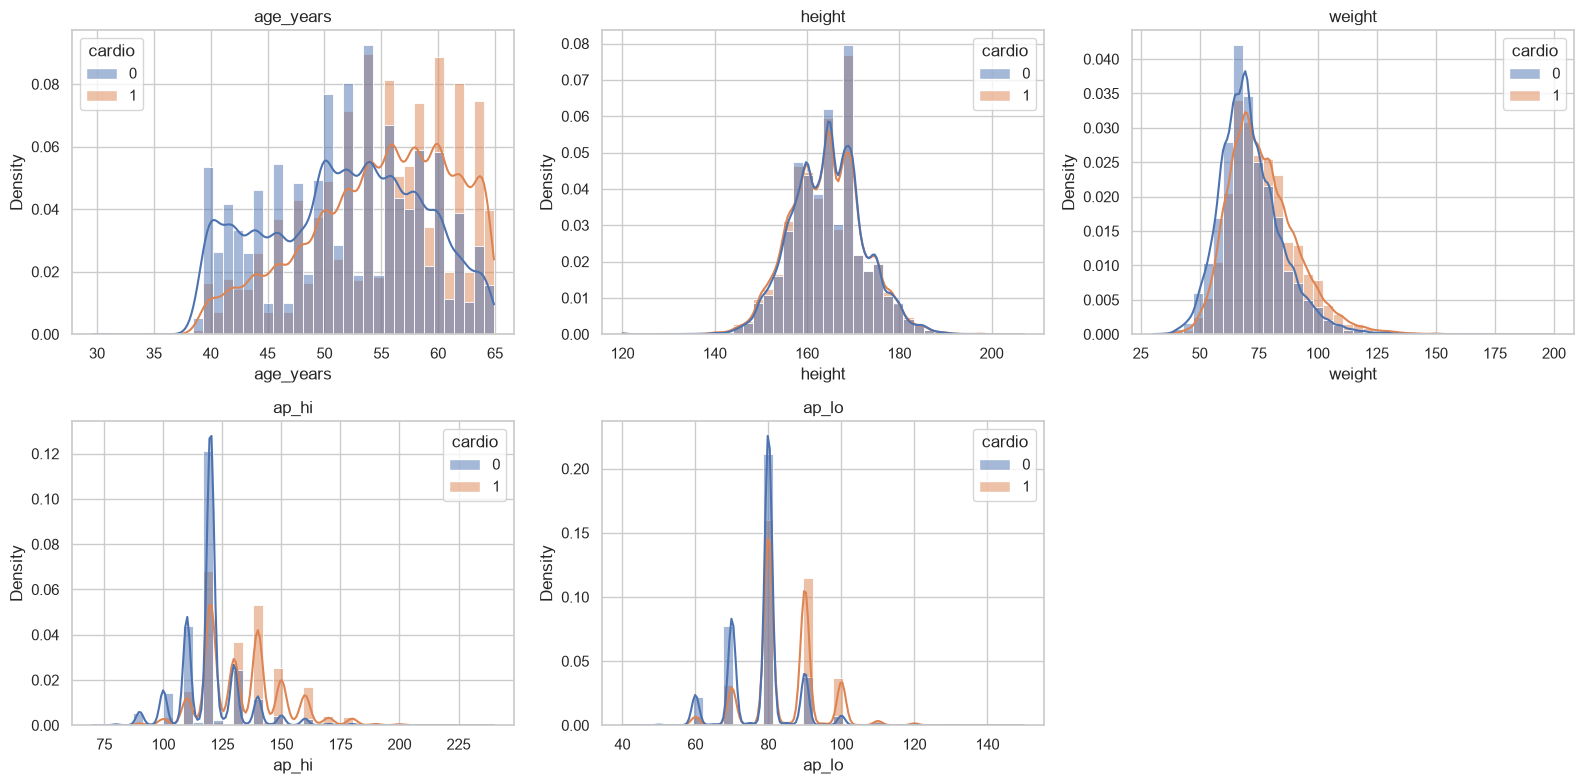

In [18]:
num_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue="cardio", kde=True, bins=40, ax=ax, stat="density", common_norm=False)
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [19]:
display(df.groupby("cardio")[num_cols].agg(["mean", "median"]).T)

cardio                0      1
age_years mean    51.69  54.93
          median  52.00  55.80
height    mean   164.51 164.32
          median 165.00 165.00
weight    mean    71.54  76.69
          median  70.00  75.00
ap_hi     mean   119.60 133.89
          median 120.00 130.00
ap_lo     mean    78.12  84.55
          median  80.00  80.00

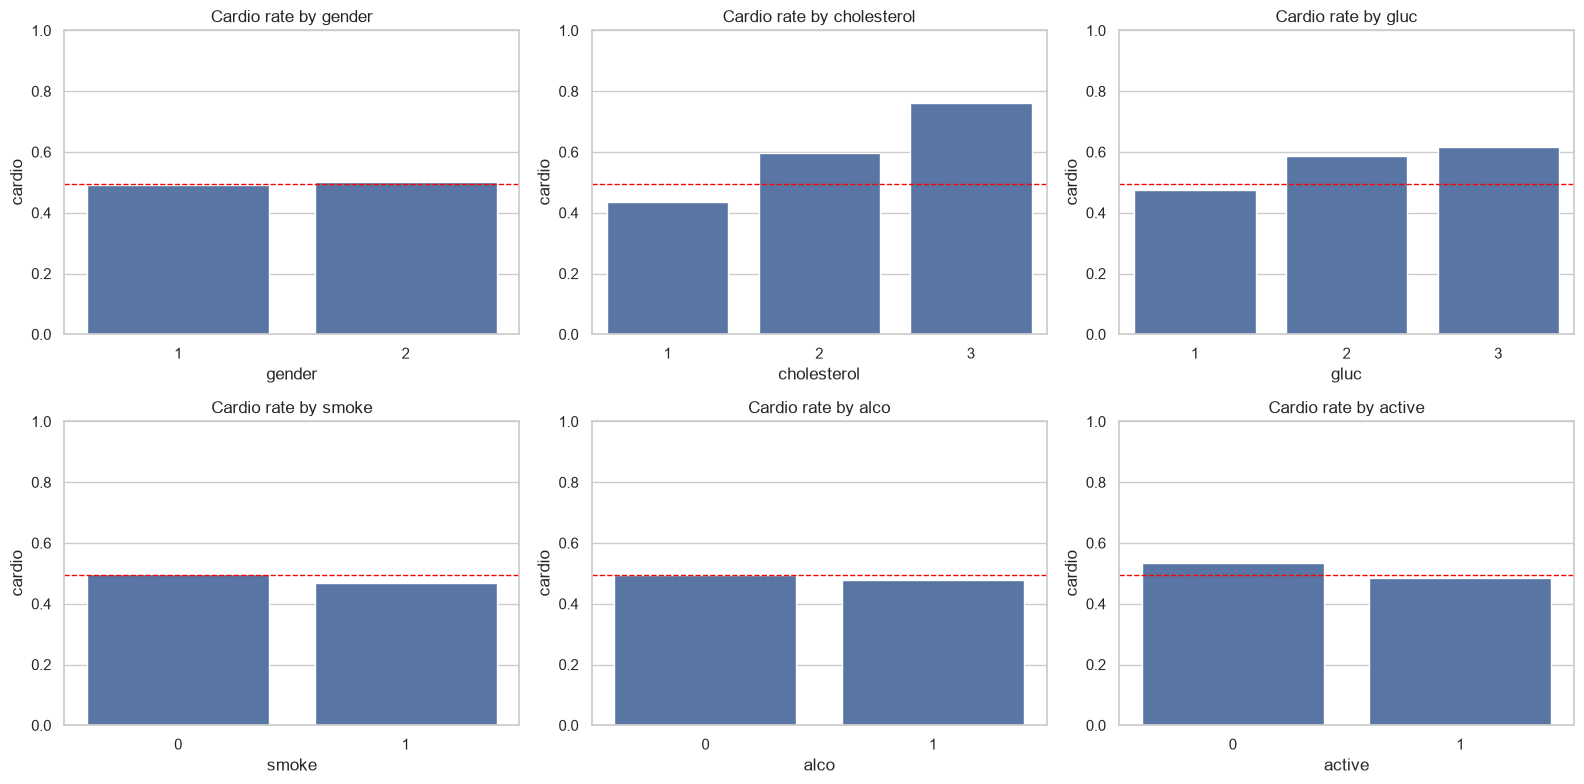

In [20]:
cat_cols = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)["cardio"].mean().reset_index()
    sns.barplot(data=rate, x=c, y="cardio", ax=ax)
    ax.set_ylim(0, 1)
    ax.axhline(df["cardio"].mean(), color="red", ls="--", lw=1)
    ax.set_title(f"Cardio rate by {c}")
plt.tight_layout()
plt.show()

In [21]:
for c in cat_cols:
    print(f"\n{c}:\n", df[c].value_counts(normalize=True).round(3).to_dict())


gender:
 {1: 0.651, 2: 0.349}

cholesterol:
 {1: 0.75, 2: 0.136, 3: 0.115}

gluc:
 {1: 0.85, 3: 0.076, 2: 0.074}

smoke:
 {0: 0.912, 1: 0.088}

alco:
 {0: 0.947, 1: 0.053}

active:
 {1: 0.803, 0: 0.197}


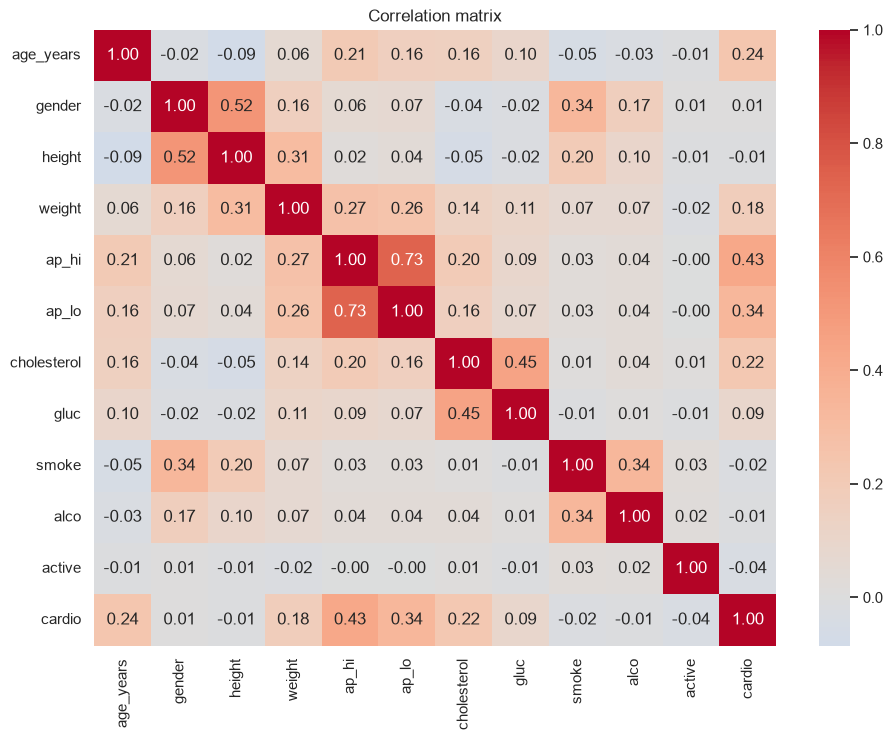

In [22]:
corr_cols = ["age_years", "gender", "height", "weight", "ap_hi", "ap_lo",
             "cholesterol", "gluc", "smoke", "alco", "active", "cardio"]

plt.figure(figsize=(11, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [23]:
print(df[corr_cols].corr()["cardio"].drop("cardio").sort_values(ascending=False).round(3))

ap_hi          0.43
ap_lo          0.34
age_years      0.24
cholesterol    0.22
weight         0.18
gluc           0.09
gender         0.01
alco          -0.01
height        -0.01
smoke         -0.02
active        -0.04
Name: cardio, dtype: float64


age_years  outliers (IQR):     4  (0.01%)
height     outliers (IQR):   447  (0.65%)
weight     outliers (IQR):  1709  (2.49%)
ap_hi      outliers (IQR):  1000  (1.46%)
ap_lo      outliers (IQR):  3493  (5.09%)


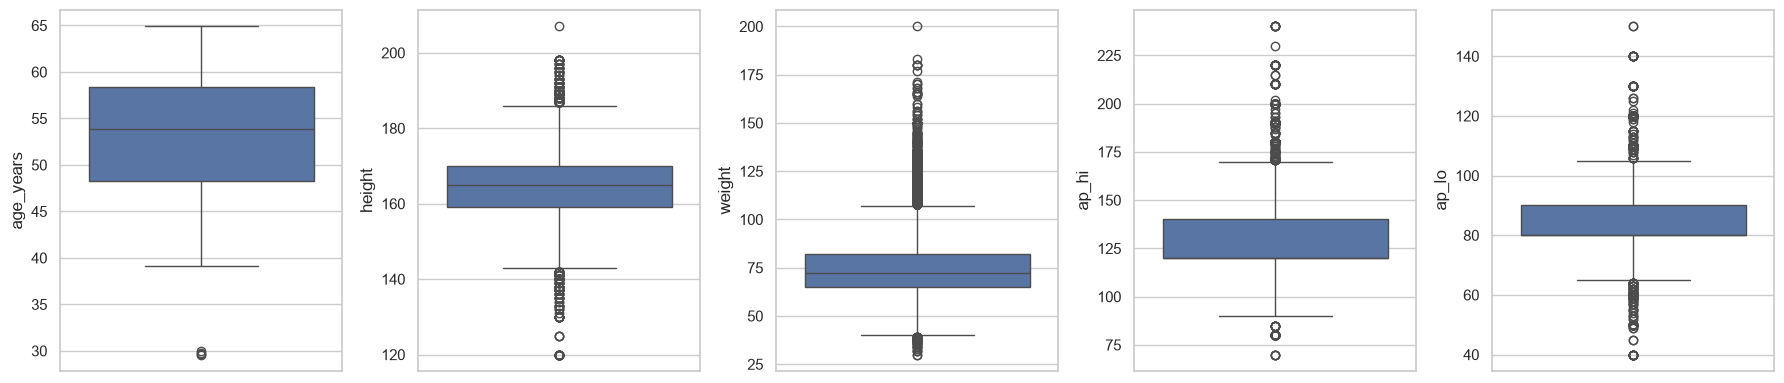

In [24]:
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c:10s} outliers (IQR): {n_out:5d}  ({n_out/len(df):.2%})")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, y=c, ax=ax)
plt.tight_layout()
plt.show()

In [25]:
# Sanity check: which gender code is male? (compare mean height)
print(df.groupby("gender")["height"].mean().round(1))

gender
1   161.40
2   170.00
Name: height, dtype: float64


In [26]:
df["gender_bin"] = (df["gender"] == 2).astype(int)

In [27]:
df["bmi"] = df["weight"] / (df["height"] / 100) ** 2

In [28]:
df["pulse_pressure"] = df["ap_hi"] - df["ap_lo"]
df["map"] = (df["ap_hi"] + 2 * df["ap_lo"]) / 3 

In [29]:
def bp_category(row):
    s, d = row["ap_hi"], row["ap_lo"]
    if s >= 140 or d >= 90: return 2      # hypertension stage 2
    if s >= 130 or d >= 80: return 1      # hypertension stage 1
    return 0                              # normal / elevated

df["bp_cat"] = df.apply(bp_category, axis=1)

df["bmi_cat"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                       labels=[0, 1, 2, 3]).astype(int)   # under / normal / over / obese

In [30]:
# Lifestyle risk score
df["risk_habits"] = df["smoke"] + df["alco"] + (1 - df["active"])

df[["bmi", "pulse_pressure", "map", "bp_cat", "bmi_cat", "risk_habits"]].describe().T

,count,mean,std,min,25%,50%,75%,max
bmi,68561.00,27.45,5.20,12.25,23.88,26.35,30.12,59.52
pulse_pressure,68561.00,45.37,11.66,5.00,40.00,40.00,50.00,140.00
map,68561.00,96.42,11.03,50.00,93.33,93.33,103.33,173.33
bp_cat,68561.00,1.16,0.71,0.00,1.00,1.00,2.00,2.00
bmi_cat,68561.00,1.87,0.81,0.00,1.00,2.00,3.00,3.00
risk_habits,68561.00,0.34,0.57,0.00,0.00,0.00,1.00,3.00


Correlation with cardio:
ap_hi            0.43
map              0.41
bp_cat           0.41
ap_lo            0.34
pulse_pressure   0.34
age_years        0.24
bmi              0.19
bmi_cat          0.18
weight           0.18
risk_habits      0.01
gender_bin       0.01
dtype: float64


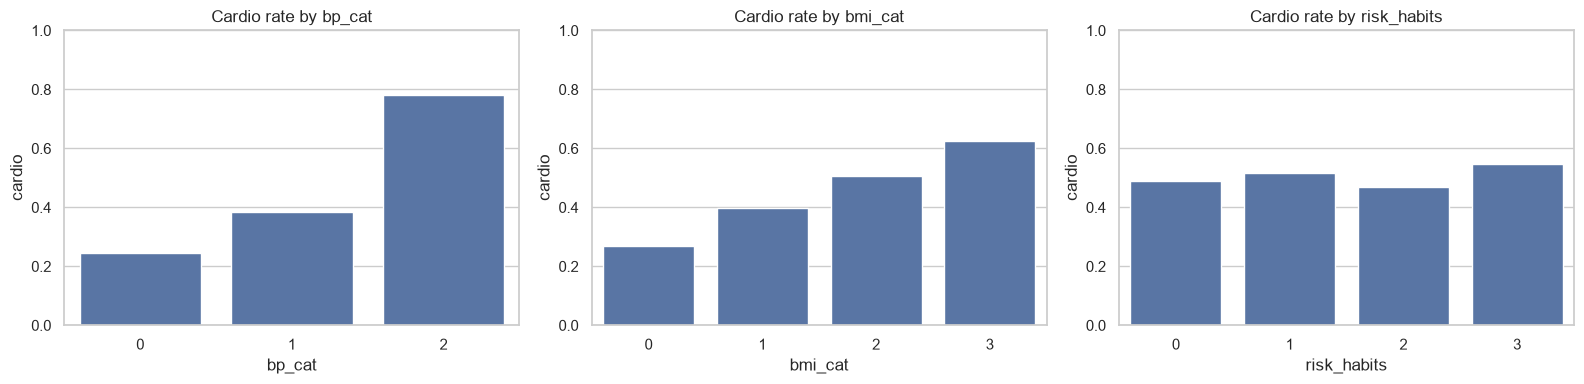

In [31]:
# Cell 14: Do the new features carry signal?
new_feats = ["bmi", "pulse_pressure", "map", "bp_cat", "bmi_cat", "risk_habits", "gender_bin"]

print("Correlation with cardio:")
print(df[new_feats + ["ap_hi", "ap_lo", "weight", "age_years"]]
      .corrwith(df["cardio"]).sort_values(ascending=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["bp_cat", "bmi_cat", "risk_habits"]):
    sns.barplot(data=df.groupby(c)["cardio"].mean().reset_index(), x=c, y="cardio", ax=ax)
    ax.set_ylim(0, 1); ax.set_title(f"Cardio rate by {c}")
plt.tight_layout(); plt.show()

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
drop_cols = ["id", "age", "gender", "cardio"]
X = df.drop(columns=drop_cols)
y = df["cardio"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

In [34]:
print("Features:", list(X.columns))
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("Target ratio  train:", y_train.mean().round(4), "| test:", y_test.mean().round(4))

Features: ['height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'gender_bin', 'bmi', 'pulse_pressure', 'map', 'bp_cat', 'bmi_cat', 'risk_habits']
Train: (54848, 17) | Test: (13713, 17)
Target ratio  train: 0.4947 | test: 0.4947


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

In [36]:
continuous = ["height", "weight", "ap_hi", "ap_lo", "age_years", "bmi", "pulse_pressure", "map"]
ordinal    = ["cholesterol", "gluc", "bp_cat", "bmi_cat", "risk_habits"]
binary     = ["smoke", "alco", "active", "gender_bin"] 

In [37]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), continuous + ordinal),
        ("bin", "passthrough", binary),
    ],
    remainder="drop",
)

assert set(continuous + ordinal + binary) == set(X_train.columns), "some column is not assigned!"
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scale', ...), ('bin', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name

In [38]:
Xtr_t = preprocessor.fit_transform(X_train)
Xte_t = preprocessor.transform(X_test)

In [39]:
print("Train transformed:", Xtr_t.shape, "| Test transformed:", Xte_t.shape)
print("Train mean ~0:", Xtr_t[:, :13].mean().round(3), "| std ~1:", Xtr_t[:, :13].std().round(3))
print("Test  mean (not exactly 0, and that is expected):", Xte_t[:, :13].mean().round(3))

Train transformed: (54848, 17) | Test transformed: (13713, 17)
Train mean ~0: 0.0 | std ~1: 1.0
Test  mean (not exactly 0, and that is expected): -0.002


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

In [41]:
groups = {
    "demographics": ["age_years", "gender_bin"],
    "body":         ["height", "weight", "bmi", "bmi_cat"],
    "bp_raw":       ["ap_hi", "ap_lo"],
    "bp_derived":   ["pulse_pressure", "map", "bp_cat"],
    "labs":         ["cholesterol", "gluc"],
    "lifestyle":    ["smoke", "alco", "active", "risk_habits"],
}

def make_pipe(cols):
    """Preprocessing + SVM, using only the given columns."""
    pre = ColumnTransformer([
        ("scale", StandardScaler(), [c for c in continuous + ordinal if c in cols]),
        ("bin", "passthrough", [c for c in binary if c in cols]),
    ])
    return Pipeline([("pre", pre),
                     ("svm", SVC(kernel="rbf", C=1, gamma="scale", random_state=RANDOM_STATE))])

In [42]:
X_sub = X_train.sample(20000, random_state=RANDOM_STATE)
y_sub = y_train.loc[X_sub.index]

In [43]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE) 

def run(cols):
    r = cross_validate(make_pipe(cols), X_sub[cols], y_sub, cv=cv,
                       scoring=["accuracy", "roc_auc"], n_jobs=-1)
    return r["test_accuracy"], r["test_roc_auc"]

In [44]:
all_cols = list(X_train.columns)
base_acc, base_auc = run(all_cols)
print(f"ALL features -> acc {base_acc.mean():.4f} | auc {base_auc.mean():.4f}")

ALL features -> acc 0.7304 | auc 0.7853


In [45]:
rows = []
for g, cols in groups.items():
    keep = [c for c in all_cols if c not in cols]
    a, u = run(keep)
    rows.append({"dropped_group": g,
                 "acc": a.mean(),
                 "d_acc": (a - base_acc).mean(),
                 "d_acc_sd": (a - base_acc).std(),
                 "auc": u.mean(),
                 "d_auc": (u - base_auc).mean()})
    print("done:", g)

done: demographics
done: body
done: bp_raw
done: bp_derived
done: labs
done: lifestyle


In [46]:
# Results table
ablation = pd.DataFrame(rows).sort_values("d_auc")
display(ablation.round(4))

,dropped_group,acc,d_acc,d_acc_sd,auc,d_auc
0,demographics,0.72,-0.01,0.00,0.77,-0.02
4,labs,0.72,-0.01,0.00,0.78,-0.01
1,body,0.73,0.00,0.00,0.78,-0.00
5,lifestyle,0.73,-0.00,0.00,0.78,-0.00
2,bp_raw,0.73,-0.00,0.00,0.79,-0.00
3,bp_derived,0.73,0.00,0.00,0.79,0.00


In [47]:
display(ablation.style.format({c: "{:.4f}" for c in ablation.columns if c != "dropped_group"}))

,dropped_group,acc,d_acc,d_acc_sd,auc,d_auc
0,demographics,0.7245,-0.0060,0.0016,0.7665,-0.0189
4,labs,0.7210,-0.0094,0.0041,0.7755,-0.0098
1,body,0.7317,0.0013,0.0029,0.7813,-0.0040
5,lifestyle,0.7294,-0.0010,0.0014,0.7823,-0.0030
2,bp_raw,0.7289,-0.0015,0.0014,0.7853,-0.0001
3,bp_derived,0.7337,0.0032,0.0024,0.7898,0.0045


In [48]:
scenarios = {
    "drop bp_derived":                 ["bp_derived"],
    "drop bp_raw":                     ["bp_raw"],
    "drop bp_derived + body":          ["bp_derived", "body"],
    "drop bp_derived + lifestyle":     ["bp_derived", "lifestyle"],
    "drop bp_derived + body + life.":  ["bp_derived", "body", "lifestyle"],
    "drop bp_derived + bp_raw (control)": ["bp_derived", "bp_raw"],   # no BP at all, expected to hurt a lot
}

In [49]:
rows2 = []
for name, gs in scenarios.items():
    drop = sum([groups[g] for g in gs], [])
    keep = [c for c in all_cols if c not in drop]
    a, u = run(keep)
    rows2.append({"scenario": name, "n_features": len(keep),
                  "acc": a.mean(), "d_acc": (a - base_acc).mean(),
                  "auc": u.mean(), "d_auc": (u - base_auc).mean(),
                  "d_auc_sd": (u - base_auc).std()})
    print("done:", name)

done: drop bp_derived
done: drop bp_raw
done: drop bp_derived + body
done: drop bp_derived + lifestyle
done: drop bp_derived + body + life.
done: drop bp_derived + bp_raw (control)


In [50]:
# Results
res2 = pd.DataFrame(rows2).sort_values("d_auc", ascending=False)
display(res2.style.format({c: "{:.4f}" for c in res2.columns if c not in ("scenario", "n_features")}))

,scenario,n_features,acc,d_acc,auc,d_auc,d_auc_sd
0,drop bp_derived,14,0.7337,0.0032,0.7898,0.0045,0.0014
3,drop bp_derived + lifestyle,10,0.7318,0.0014,0.7880,0.0027,0.0046
2,drop bp_derived + body,10,0.7331,0.0026,0.7860,0.0006,0.0042
1,drop bp_raw,15,0.7289,-0.0015,0.7853,-0.0001,0.0006
4,drop bp_derived + body + life.,6,0.7310,0.0006,0.7824,-0.0029,0.0056
5,drop bp_derived + bp_raw (control),12,0.6427,-0.0877,0.6891,-0.0962,0.0079


In [51]:
drop_final = groups["bp_derived"]                       # pulse_pressure, map, bp_cat
selected = [c for c in X_train.columns if c not in drop_final]

X_train_sel = X_train[selected]
X_test_sel  = X_test[selected]          # kept aside, NOT used until the very end

print(len(selected), "features:", selected)

14 features: ['height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'gender_bin', 'bmi', 'bmi_cat', 'risk_habits']


In [52]:
import time
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

t0 = time.time()
base_cv = cross_validate(make_pipe(selected), X_train_sel, y_train, cv=cv,
                         scoring=scoring, n_jobs=-1, return_train_score=True)
print(f"Done in {time.time() - t0:.0f}s")

Done in 605s


In [53]:
baseline_table = pd.DataFrame({
    "metric": scoring,
    "val_mean":   [base_cv[f"test_{m}"].mean() for m in scoring],
    "val_std":    [base_cv[f"test_{m}"].std()  for m in scoring],
    "train_mean": [base_cv[f"train_{m}"].mean() for m in scoring],
})
baseline_table["gap"] = baseline_table["train_mean"] - baseline_table["val_mean"]
display(baseline_table.style.format({c: "{:.4f}" for c in baseline_table.columns if c != "metric"}))
print(f"Avg fit time per fold: {base_cv['fit_time'].mean():.0f}s")

,metric,val_mean,val_std,train_mean,gap
0,accuracy,0.7341,0.0037,0.7395,0.0054
1,precision,0.7621,0.0053,0.7686,0.0065
2,recall,0.6724,0.0037,0.6774,0.0050
3,f1,0.7144,0.0037,0.7201,0.0057
4,roc_auc,0.7901,0.0047,0.8016,0.0115


Avg fit time per fold: 158s


In [54]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

In [55]:
Xs = X_train_sel.sample(15000, random_state=RANDOM_STATE)
ys = y_train.loc[Xs.index]

param_dist = [
    {"svm__kernel": ["rbf"],
     "svm__C": loguniform(0.3, 20),
     "svm__gamma": loguniform(0.003, 0.1)},
    {"svm__kernel": ["linear"],
     "svm__C": loguniform(0.01, 10)},
]

search = RandomizedSearchCV(
    make_pipe(selected), param_dist, n_iter=20, scoring="roc_auc",
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1, random_state=RANDOM_STATE, refit=False,
)

t0 = time.time()
search.fit(Xs, ys)
print(f"Done in {time.time() - t0:.0f}s")

Done in 63s


In [56]:
res = pd.DataFrame(search.cv_results_)[[
    "param_svm__kernel", "param_svm__C", "param_svm__gamma",
    "mean_test_score", "std_test_score", "mean_fit_time"]]
res = res.sort_values("mean_test_score", ascending=False).reset_index(drop=True)
display(res.head(10).style.format({"param_svm__C": "{:.4f}", "param_svm__gamma": "{:.4f}",
                                   "mean_test_score": "{:.4f}", "std_test_score": "{:.4f}",
                                   "mean_fit_time": "{:.1f}"}))
print("Best params:", search.best_params_)

,param_svm__kernel,param_svm__C,param_svm__gamma,mean_test_score,std_test_score,mean_fit_time
0,rbf,8.5103,0.0057,0.7964,0.0049,6.1
1,rbf,1.8406,0.0083,0.7961,0.0048,6.9
2,rbf,3.8479,0.0055,0.7959,0.0048,7.2
3,rbf,1.9511,0.0043,0.7953,0.0049,6.7
4,rbf,1.6085,0.0035,0.7951,0.0047,6.8
5,rbf,0.3208,0.0067,0.7945,0.0044,6.0
6,linear,0.0101,nan,0.7942,0.0042,5.4
7,rbf,18.6399,0.0154,0.7942,0.0059,8.9
8,linear,0.0187,nan,0.7941,0.0042,5.5
9,linear,0.0397,nan,0.7941,0.0042,5.6


Best params: {'svm__C': np.float64(8.51026279077542), 'svm__gamma': np.float64(0.005707819059849824), 'svm__kernel': 'rbf'}


In [57]:
best_params = {"svm__kernel": "rbf", "svm__C": 1.8406, "svm__gamma": 0.0083}

# For reference: what gamma='scale' (the baseline) actually equals on our data
Xt = make_pipe(selected).named_steps["pre"].fit_transform(X_train_sel)
print("Baseline gamma ('scale'):", round(1 / (Xt.shape[1] * Xt.var()), 4), "| tuned gamma:", best_params["svm__gamma"])

Baseline gamma ('scale'): 0.0895 | tuned gamma: 0.0083


In [58]:
tuned_pipe = make_pipe(selected).set_params(**best_params)

t0 = time.time()
tuned_cv = cross_validate(tuned_pipe, X_train_sel, y_train, cv=cv,
                          scoring=scoring, n_jobs=-1, return_train_score=True)
print(f"Done in {time.time() - t0:.0f}s")

Done in 609s


In [59]:
rows = []
for m in scoring:
    b, t = base_cv[f"test_{m}"], tuned_cv[f"test_{m}"]
    rows.append({"metric": m,
                 "baseline": b.mean(), "tuned": t.mean(),
                 "improvement": (t - b).mean(), "improvement_sd": (t - b).std(),
                 "train_gap_tuned": (tuned_cv[f"train_{m}"] - t).mean()})
compare = pd.DataFrame(rows)
display(compare.style.format({c: "{:.4f}" for c in compare.columns if c != "metric"}))
print(f"Avg fit time per fold - baseline: {base_cv['fit_time'].mean():.0f}s | tuned: {tuned_cv['fit_time'].mean():.0f}s")

,metric,baseline,tuned,improvement,improvement_sd,train_gap_tuned
0,accuracy,0.7341,0.7320,-0.0020,0.0021,0.0006
1,precision,0.7621,0.7599,-0.0023,0.0017,0.0010
2,recall,0.6724,0.6702,-0.0022,0.0034,0.0000
3,f1,0.7144,0.7122,-0.0022,0.0026,0.0005
4,roc_auc,0.7901,0.7935,0.0034,0.0007,0.0010


Avg fit time per fold - baseline: 158s | tuned: 127s


In [60]:
from sklearn.model_selection import cross_val_predict

t0 = time.time()
oof_scores = cross_val_predict(tuned_pipe, X_train_sel, y_train, cv=cv,
                               method="decision_function", n_jobs=-1)
print(f"Done in {time.time() - t0:.0f}s")

Done in 179s


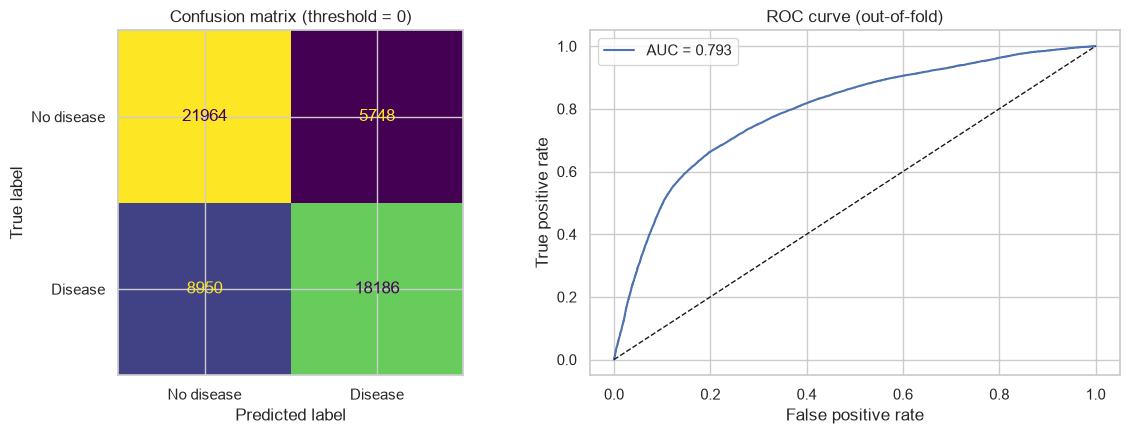

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

y_pred_default = (oof_scores > 0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_train, y_pred_default),
                       display_labels=["No disease", "Disease"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (threshold = 0)")

fpr, tpr, _ = roc_curve(y_train, oof_scores)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_train, oof_scores):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (out-of-fold)"); axes[1].legend()
plt.tight_layout(); plt.show()

In [62]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

rows = []
for th in np.arange(-0.6, 0.61, 0.1):
    p = (oof_scores > th).astype(int)
    rows.append({"threshold": th,
                 "accuracy": accuracy_score(y_train, p),
                 "precision": precision_score(y_train, p),
                 "recall": recall_score(y_train, p),
                 "f1": f1_score(y_train, p)})
th_table = pd.DataFrame(rows)
display(th_table.style.format("{:.3f}").highlight_max(subset=["accuracy", "f1"], color="#d4edda"))

,threshold,accuracy,precision,recall,f1
0,-0.600,0.713,0.678,0.800,0.734
1,-0.500,0.720,0.693,0.780,0.734
2,-0.400,0.724,0.706,0.758,0.731
3,-0.300,0.728,0.721,0.736,0.728
4,-0.200,0.729,0.734,0.711,0.722
5,-0.100,0.730,0.747,0.688,0.717
6,-0.000,0.732,0.760,0.670,0.712
7,0.100,0.731,0.773,0.645,0.704
8,0.200,0.728,0.784,0.622,0.694
9,0.300,0.726,0.794,0.603,0.685


In [63]:
THRESHOLD = -0.3

def metrics_at(th):
    p = (oof_scores > th).astype(int)
    return {"threshold": th,
            "accuracy": accuracy_score(y_train, p), "precision": precision_score(y_train, p),
            "recall": recall_score(y_train, p), "f1": f1_score(y_train, p)}

display(pd.DataFrame([metrics_at(0.0), metrics_at(THRESHOLD)], index=["default", "chosen"])
        .style.format("{:.3f}"))

,threshold,accuracy,precision,recall,f1
default,0.000,0.732,0.760,0.670,0.712
chosen,-0.300,0.728,0.721,0.736,0.728


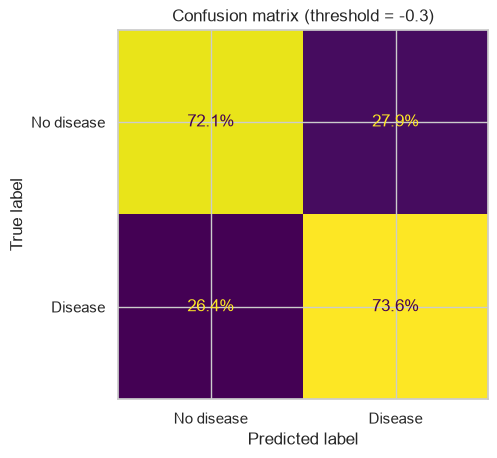

In [64]:
ConfusionMatrixDisplay.from_predictions(
    y_train, (oof_scores > THRESHOLD).astype(int), normalize="true",
    display_labels=["No disease", "Disease"], values_format=".1%", colorbar=False)
plt.title(f"Confusion matrix (threshold = {THRESHOLD})")
plt.show()

In [65]:
final_pipe = make_pipe(selected).set_params(**best_params)

t0 = time.time()
final_pipe.fit(X_train_sel, y_train)
print(f"Fitted in {time.time() - t0:.0f}s on {len(X_train_sel)} rows | {len(selected)} features")

Fitted in 126s on 54848 rows | 14 features


In [66]:
# FINAL TEST (first and only evaluation on the test set)
test_scores = final_pipe.decision_function(X_test_sel)

rows = []
for name, th in [("default (0.0)", 0.0), (f"chosen ({THRESHOLD})", THRESHOLD)]:
    p = (test_scores > th).astype(int)
    rows.append({"setting": name,
                 "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p), "f1": f1_score(y_test, p),
                 "roc_auc": roc_auc_score(y_test, test_scores)})
test_results = pd.DataFrame(rows).set_index("setting")
display(test_results.style.format("{:.4f}"))

,accuracy,precision,recall,f1,roc_auc
setting,,,,,
default (0.0),0.7295,0.7565,0.6683,0.7097,0.7927
chosen (-0.3),0.7249,0.7161,0.7354,0.7256,0.7927


CV estimate on train (chosen threshold):


,accuracy,precision,recall,f1
0,0.7284,0.7208,0.7361,0.7284


              precision    recall  f1-score   support

  No disease      0.734     0.715     0.724      6929
     Disease      0.716     0.735     0.726      6784

    accuracy                          0.725     13713
   macro avg      0.725     0.725     0.725     13713
weighted avg      0.725     0.725     0.725     13713



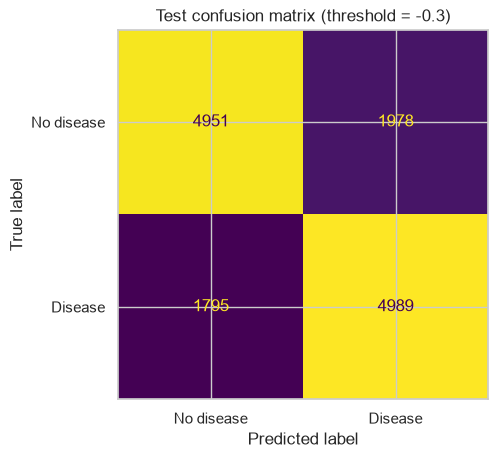

In [67]:
# Compare with the cross-validation estimate on TRAIN (should be close if there is no leakage/overfitting)
cv_ref = pd.DataFrame([metrics_at(THRESHOLD)]).drop(columns="threshold")
print("CV estimate on train (chosen threshold):")
display(cv_ref.style.format("{:.4f}"))
#---------------------------
from sklearn.metrics import classification_report
#---------------------------
y_pred_test = (test_scores > THRESHOLD).astype(int)
print(classification_report(y_test, y_pred_test, target_names=["No disease", "Disease"], digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test,
    display_labels=["No disease", "Disease"], colorbar=False)
plt.title(f"Test confusion matrix (threshold = {THRESHOLD})")
plt.show()

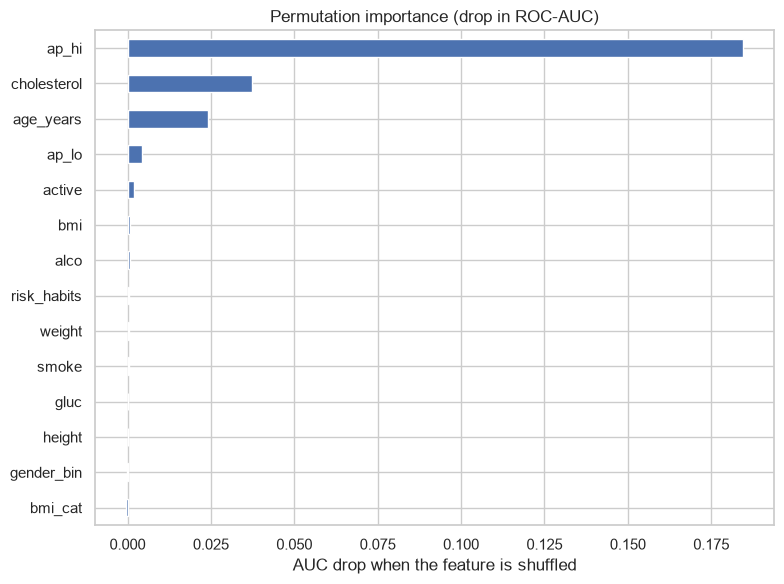

In [68]:
from sklearn.inspection import permutation_importance

idx = X_test_sel.sample(3000, random_state=RANDOM_STATE).index
pi = permutation_importance(final_pipe, X_test_sel.loc[idx], y_test.loc[idx],
                            scoring="roc_auc", n_repeats=3,
                            random_state=RANDOM_STATE, n_jobs=-1)

imp = pd.Series(pi.importances_mean, index=selected).sort_values()
imp.plot.barh(figsize=(8, 6), title="Permutation importance (drop in ROC-AUC)")
plt.xlabel("AUC drop when the feature is shuffled")
plt.tight_layout(); plt.show()

In [69]:
# Save the final model and test it on a brand-new patient
import joblib

joblib.dump({"pipeline": final_pipe, "threshold": THRESHOLD, "features": selected},
            "cardio_svm_final.joblib")

def predict_patient(age_years, gender, height, weight, ap_hi, ap_lo,
                    cholesterol, gluc, smoke, alco, active, model_path="cardio_svm_final.joblib"):
    """gender: 1 = female, 2 = male | cholesterol/gluc: 1 normal, 2 above normal, 3 well above"""
    art = joblib.load(model_path)
    bmi = weight / (height / 100) ** 2
    row = pd.DataFrame([{
        "height": height, "weight": weight, "ap_hi": ap_hi, "ap_lo": ap_lo,
        "cholesterol": cholesterol, "gluc": gluc, "smoke": smoke, "alco": alco, "active": active,
        "age_years": age_years, "gender_bin": int(gender == 2), "bmi": bmi,
        "bmi_cat": int(pd.cut([bmi], bins=[0, 18.5, 25, 30, 100], labels=[0, 1, 2, 3])[0]),
        "risk_habits": smoke + alco + (1 - active),
    }])[art["features"]]
    score = art["pipeline"].decision_function(row)[0]
    return {"score": round(float(score), 3), "prediction": "Disease" if score > art["threshold"] else "No disease"}

In [70]:
print(predict_patient(age_years=55, gender=2, height=172, weight=92, ap_hi=150, ap_lo=95,
                      cholesterol=3, gluc=1, smoke=0, alco=0, active=0))
print(predict_patient(age_years=35, gender=1, height=165, weight=58, ap_hi=110, ap_lo=70,
                      cholesterol=1, gluc=1, smoke=0, alco=0, active=1))

{'score': 1.48, 'prediction': 'Disease'}
{'score': -1.597, 'prediction': 'No disease'}


In [71]:
# Save the output data files (deliverables)
df.to_csv("cardio_clean.csv", index=False)                                   # cleaned + engineered data
X_train_sel.assign(cardio=y_train).to_csv("cardio_train.csv", index=False)   # train split (14 selected features)
X_test_sel.assign(cardio=y_test).to_csv("cardio_test.csv", index=False)      # test split

print("Saved: cardio_clean.csv", df.shape,
      "| cardio_train.csv", X_train_sel.shape, "| cardio_test.csv", X_test_sel.shape)

Saved: cardio_clean.csv (68561, 21) | cardio_train.csv (54848, 14) | cardio_test.csv (13713, 14)
